# 1.0 IMPORTING LIBRARIES

In [148]:
import warnings
warnings.filterwarnings("ignore")

!pip install pyspark

In [149]:
import pyspark # only run after findspark.init()
from pyspark.sql import SparkSession
import seaborn as sns

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt

import sklearn
import random
import os
    
from pyspark.sql import SQLContext  
from pyspark.sql.functions import mean,col,split, col, regexp_extract, when, lit
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.feature import QuantileDiscretizer


# LOAD PYSPARK LIBRARIES FOR LOGISTIC DECISION TREE CLASSIFIER
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from sklearn.metrics import roc_curve,auc
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.regression import LinearRegression
from pyspark.mllib.evaluation import RegressionMetrics
from pyspark.ml.feature import VectorAssembler, StandardScaler


# 2.0 EDA

- `import dataset`
- `describe dataset`
- `show dataframe columns`
- `printSchema of dataframe`
- `dtypes`
- `head`
- `tails`
- `Show rows of the DataFrame`
- `summary statistics`
- `Count the number of null values`
- `cross tabulation`
- `groupby`
- `convert from string ti index`
- `bar plot`
- `pivot table`
- `scatter plot`

In [150]:
#import dataset

file = 'FactSalesTargets.csv'

spark = SparkSession.builder.appName("Fact Sales Targets").config('spark.sql.debug.maxToStringFields', 2000).getOrCreate()
df = spark.read.csv(file, header=True, inferSchema=True)

In [78]:
#describe the data 

df.describe()

DataFrame[summary: string, Row: string, SalesTerritoryKey: string, SalesTerritoryRegion: string, SalesTerritoryGroup: string, SalesTerritoryCountry: string, CalendarYear: string, DateKey: string, SalesAmountQuote: string]

In [180]:
# show the dataframe columns
df.columns

['Row',
 'SalesTerritoryKey',
 'SalesTerritoryRegion',
 'SalesTerritoryGroup',
 'SalesTerritoryCountry',
 'CalendarYear',
 'DateKey',
 'SalesAmountQuote']

In [79]:
# View the schema of the DataFrame

df.printSchema()

root
 |-- Row: integer (nullable = true)
 |-- SalesTerritoryKey: integer (nullable = true)
 |-- SalesTerritoryRegion: string (nullable = true)
 |-- SalesTerritoryGroup: string (nullable = true)
 |-- SalesTerritoryCountry: string (nullable = true)
 |-- CalendarYear: integer (nullable = true)
 |-- DateKey: string (nullable = true)
 |-- SalesAmountQuote: integer (nullable = true)



In [134]:
# View column type

df.dtypes

[('Row', 'int'),
 ('SalesTerritoryKey', 'int'),
 ('SalesTerritoryRegion', 'string'),
 ('SalesTerritoryGroup', 'string'),
 ('SalesTerritoryCountry', 'string'),
 ('CalendarYear', 'int'),
 ('DateKey', 'string'),
 ('SalesAmountQuote', 'int')]

In [133]:
# view columns head

df.head()

Row(Row=1, SalesTerritoryKey=1, SalesTerritoryRegion='Northwest', SalesTerritoryGroup='North America', SalesTerritoryCountry='United States', CalendarYear=2006, DateKey='01/01/2006', SalesAmountQuote=2693000)

In [132]:
# view columns tail

df.tail(5)

[Row(Row=34, SalesTerritoryKey=10, SalesTerritoryRegion='United Kingdom', SalesTerritoryGroup='Europe', SalesTerritoryCountry='United Kingdom', CalendarYear=2006, DateKey='01/01/2006', SalesAmountQuote=3160000),
 Row(Row=35, SalesTerritoryKey=11, SalesTerritoryRegion='NA', SalesTerritoryGroup='NA', SalesTerritoryCountry='NA', CalendarYear=2006, DateKey='01/01/2006', SalesAmountQuote=563000),
 Row(Row=36, SalesTerritoryKey=11, SalesTerritoryRegion='NA', SalesTerritoryGroup='NA', SalesTerritoryCountry='NA', CalendarYear=2007, DateKey='01/01/2007', SalesAmountQuote=1367000),
 Row(Row=37, SalesTerritoryKey=11, SalesTerritoryRegion='NA', SalesTerritoryGroup='NA', SalesTerritoryCountry='NA', CalendarYear=2008, DateKey='01/01/2008', SalesAmountQuote=421000),
 Row(Row=38, SalesTerritoryKey=11, SalesTerritoryRegion='NA', SalesTerritoryGroup='NA', SalesTerritoryCountry='NA', CalendarYear=2005, DateKey='01/01/2005', SalesAmountQuote=35000)]

In [211]:
# Show the first few rows of the DataFrame

df.show(10)

+---+-----------------+--------------------+-------------------+---------------------+------------+----------+----------------+
|Row|SalesTerritoryKey|SalesTerritoryRegion|SalesTerritoryGroup|SalesTerritoryCountry|CalendarYear|   DateKey|SalesAmountQuote|
+---+-----------------+--------------------+-------------------+---------------------+------------+----------+----------------+
|  1|                1|           Northwest|      North America|        United States|        2006|01/01/2006|         2693000|
|  2|                1|           Northwest|      North America|        United States|        2007|01/01/2007|         4102000|
|  3|                1|           Northwest|      North America|        United States|        2008|01/01/2008|         2321000|
|  4|                1|           Northwest|      North America|        United States|        2005|01/01/2005|         1213000|
|  5|                2|           Northeast|      North America|        United States|        2005|01/01

In [82]:
# Count

df.count()

38

In [209]:
# Summary statistics

df.describe().show(5)

+-------+------------------+-----------------+--------------------+-------------------+---------------------+------------------+----------+------------------+
|summary|               Row|SalesTerritoryKey|SalesTerritoryRegion|SalesTerritoryGroup|SalesTerritoryCountry|      CalendarYear|   DateKey|  SalesAmountQuote|
+-------+------------------+-----------------+--------------------+-------------------+---------------------+------------------+----------+------------------+
|  count|                38|               38|                  38|                 38|                   38|                38|        38|                38|
|   mean|              19.5|5.605263157894737|                null|               null|                 null|2006.6842105263158|      null|2518789.4736842103|
| stddev|11.113055385446435|3.251107700496493|                null|               null|                 null|1.0931052509323678|      null|1692913.3877031575|
|    min|                 1|                1|

In [210]:
# statistical summary of dataset

numeric_features = [t[0] for t in df.dtypes if t[1] == 'int']
df.select(numeric_features).describe().toPandas().transpose()

,0,1,2,3,4
summary,count,mean,stddev,min,max
Row,38,19.5,11.113055385446435,1,38
SalesTerritoryKey,38,5.605263157894737,3.251107700496493,1,11
CalendarYear,38,2006.6842105263158,1.0931052509323678,2005,2008
SalesAmountQuote,38,2518789.4736842103,1692913.3877031575,35000,7326000


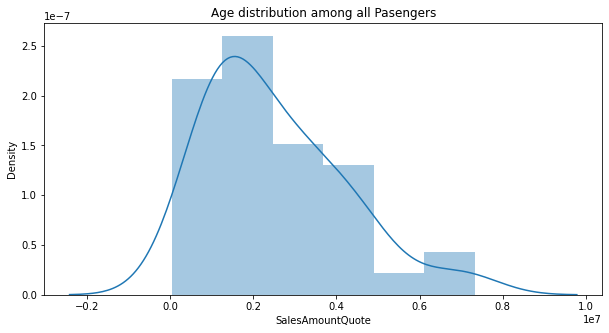

In [84]:
pandas_df = df.toPandas()

plt.figure(figsize=(10,5))
plt.title('Age distribution among all Pasengers')
sns.distplot(pandas_df['SalesAmountQuote']);

In [85]:
# Count the number of null values in each column

from pyspark.sql.functions import isnan, when, count, col
df.select([count(when(isnan(c) | col(c).isNull(), c)).alias(c) for c in df.columns]).show()

+---+-----------------+--------------------+-------------------+---------------------+------------+-------+----------------+
|Row|SalesTerritoryKey|SalesTerritoryRegion|SalesTerritoryGroup|SalesTerritoryCountry|CalendarYear|DateKey|SalesAmountQuote|
+---+-----------------+--------------------+-------------------+---------------------+------------+-------+----------------+
|  0|                0|                   0|                  0|                    0|           0|      0|               0|
+---+-----------------+--------------------+-------------------+---------------------+------------+-------+----------------+



In [86]:
# Computation of cross-tabulation of two columns

df.crosstab('CalendarYear', 'SalesAmountQuote')

DataFrame[CalendarYear_SalesAmountQuote: string, 1002000: bigint, 1213000: bigint, 1224000: bigint, 1294000: bigint, 1367000: bigint, 1437000: bigint, 1586000: bigint, 1615000: bigint, 1661000: bigint, 1718000: bigint, 1892000: bigint, 2069000: bigint, 2212000: bigint, 2321000: bigint, 2427000: bigint, 2693000: bigint, 2768000: bigint, 2940000: bigint, 2963000: bigint, 3160000: bigint, 3356000: bigint, 35000: bigint, 3592000: bigint, 3805000: bigint, 3910000: bigint, 4102000: bigint, 421000: bigint, 4350000: bigint, 4716000: bigint, 4750000: bigint, 5142000: bigint, 563000: bigint, 6481000: bigint, 7326000: bigint, 820000: bigint, 867000: bigint, 923000: bigint, 993000: bigint]

In [87]:
# group

df.groupBy()

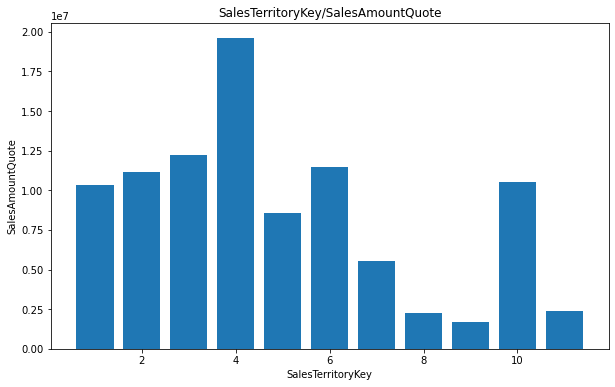

In [261]:
# For visualization convert SparkDataframe to PandasDataFrame 

from pandas import pivot_table

# create the bar plot

fig = plt.figure(figsize=(10,6))

plt.bar(x,y)
plt.xlabel('SalesTerritoryKey')
plt.ylabel('SalesAmountQuote')
plt.title('SalesTerritoryKey/SalesAmountQuote')

# show the plot

plt.show()

                   SalesAmountQuote
SalesTerritoryKey                  
1                          10329000
2                          11162000
3                          12198000
4                          19590000
5                           8541000
6                          11463000
7                           5557000
8                           2287000
9                           1687000
10                         10514000
11                          2386000


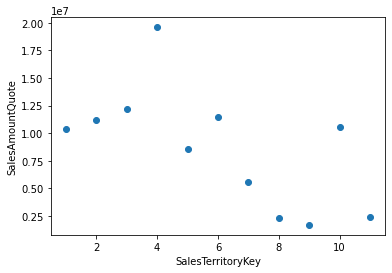

In [259]:
pandas_df = df.toPandas()

# create a pivot table

pivot_table = pivot_table(pandas_df, values='SalesAmountQuote', index='SalesTerritoryKey', aggfunc='sum')
print(pivot_table)

# reset pivot table

pandas_df = pivot_table.reset_index()

# Define the x and y axis

x = pandas_df["SalesTerritoryKey"]
y = pandas_df["SalesAmountQuote"]


# Create the scatter plot

plt.scatter(x, y)
plt.xlabel("SalesTerritoryKey")
plt.ylabel("SalesAmountQuote")
plt.show()


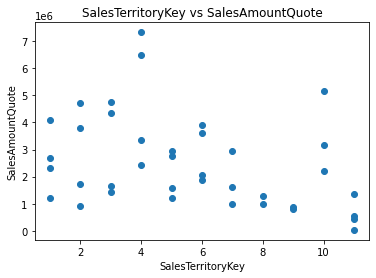

In [114]:
#Display a scatter plot of SalesTerritoryKey against SalesAmountQuote

internet_pd = df.toPandas()

#create a scatter plot of SalesTerritoryKey vs SalesAmountQuote

plt.scatter(internet_pd["SalesTerritoryKey"], internet_pd["SalesAmountQuote"])
plt.xlabel("SalesTerritoryKey")
plt.ylabel("SalesAmountQuote")
plt.title("SalesTerritoryKey vs SalesAmountQuote")
plt.show()

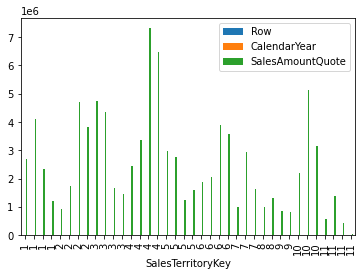

In [206]:
df.toPandas().plot.bar(x='SalesTerritoryKey');

In [88]:
# converting Sex, Embarked & Initial columns from string to number using StringIndexer

indexers = [StringIndexer(inputCol=column, outputCol=column+"_index").fit(df) for column in ["DateKey","SalesTerritoryGroup","SalesTerritoryCountry","SalesTerritoryRegion"]]
pipeline = Pipeline(stages=indexers)
df = pipeline.fit(df).transform(df)

In [89]:
df.limit(3).toPandas()

,Row,SalesTerritoryKey,SalesTerritoryRegion,SalesTerritoryGroup,SalesTerritoryCountry,CalendarYear,DateKey,SalesAmountQuote,DateKey_index,SalesTerritoryGroup_index,SalesTerritoryCountry_index,SalesTerritoryRegion_index
0,1,1,Northwest,North America,United States,2006,01/01/2006,2693000,2.0,0.0,0.0,4.0
1,2,1,Northwest,North America,United States,2007,01/01/2007,4102000,0.0,0.0,0.0,4.0
2,3,1,Northwest,North America,United States,2008,01/01/2008,2321000,1.0,0.0,0.0,4.0


In [90]:
# Now we drop columns that not needed for modelling
df = df.drop("DateKey","SalesTerritoryGroup","SalesTerritoryCountry","SalesTerritoryRegion", "Row")

# Before modelling in Pyspark, we need to put all features to Vector using Pyspark VectorAssembler
feature = VectorAssembler(inputCols = df.columns[1:],outputCol="features")
feature_vector= feature.transform(df)
feature_vector.limit(3).toPandas()

,SalesTerritoryKey,CalendarYear,SalesAmountQuote,DateKey_index,SalesTerritoryGroup_index,SalesTerritoryCountry_index,SalesTerritoryRegion_index,features
0,1,2006,2693000,2.0,0.0,0.0,4.0,"[2006.0, 2693000.0, 2.0, 0.0, 0.0, 4.0]"
1,1,2007,4102000,0.0,0.0,0.0,4.0,"[2007.0, 4102000.0, 0.0, 0.0, 0.0, 4.0]"
2,1,2008,2321000,1.0,0.0,0.0,4.0,"[2008.0, 2321000.0, 1.0, 0.0, 0.0, 4.0]"


In [92]:
# for data split in pyspark, we can use df.randomSplit()

(train_df, test_df) = feature_vector.randomSplit([0.8, 0.2],seed = 11)

In [93]:
train_df.printSchema()

root
 |-- SalesTerritoryKey: integer (nullable = true)
 |-- CalendarYear: integer (nullable = true)
 |-- SalesAmountQuote: integer (nullable = true)
 |-- DateKey_index: double (nullable = false)
 |-- SalesTerritoryGroup_index: double (nullable = false)
 |-- SalesTerritoryCountry_index: double (nullable = false)
 |-- SalesTerritoryRegion_index: double (nullable = false)
 |-- features: vector (nullable = true)



In [96]:
# load the dataset and create sprk dataframe

df=spark.read.csv('FactSalesTargets.csv',inferSchema=True,header=True)
SalesTerritoryKey_counts = df.groupBy("SalesTerritoryKey").count()
SalesTerritoryKey_counts.show()

+-----------------+-----+
|SalesTerritoryKey|count|
+-----------------+-----+
|                1|    4|
|                6|    4|
|                3|    4|
|                5|    4|
|                9|    2|
|                4|    4|
|                8|    2|
|                7|    3|
|               10|    3|
|               11|    4|
|                2|    4|
+-----------------+-----+



# 3.0 CLASSIFICATION

- `import dataset`
- `statistical summary`
- `put features into a feature vector column`
- `train dataset`
- `decision tree classifier`
- `model evaluation`

In [182]:
# import dataset

import warnings
warnings.filterwarnings("ignore")

!pip install pyspark

file2 = 'DimCustomer.csv'

spark = SparkSession.builder.appName("Fact Sales Targets").config('spark.sql.debug.maxToStringFields', 2000).getOrCreate()
df2 = spark.read.csv(file2, header=True, inferSchema=True)

In [138]:
# statistical summary of dataset

numeric_features = [t[0] for t in df2.dtypes if t[1] == 'int']
df2.select(numeric_features).describe().toPandas().transpose()

,0,1,2,3,4
summary,count,mean,stddev,min,max
CustomerKey,18484,20241.5,5336.015523465676,11000,29483
GeographyKey,18484,257.9562865180697,196.5310624611783,2,654
YearlyIncome,18484,57305.77797013633,32285.841702968246,10000,170000
TotalChildren,18484,1.8443518718892016,1.6124079348425102,0,5
NumberChildrenAtHome,18484,1.0040575632979873,1.5226596584134167,0,5
HouseOwnerFlag,18484,0.6763687513525211,0.4678738147627491,0,1
NumberCarsOwned,18484,1.5027050421986583,1.1383937411548146,0,4


In [247]:
# put features into a feature vector column

assembler = VectorAssembler(inputCols=['CustomerKey','GeographyKey','YearlyIncome','TotalChildren'] ,outputCol='features')

output = assembler.transform(df2)

df3 = output.select('features','HouseOwnerFlag')

df3.show(10)

+--------------------+--------------+
|            features|HouseOwnerFlag|
+--------------------+--------------+
|[11000.0,26.0,900...|             1|
|[11001.0,37.0,600...|             0|
|[11002.0,31.0,600...|             1|
|[11003.0,11.0,700...|             0|
|[11004.0,19.0,800...|             1|
|[11005.0,22.0,700...|             1|
|[11006.0,8.0,7000...|             1|
|[11007.0,40.0,600...|             1|
|[11008.0,32.0,600...|             1|
|[11009.0,25.0,700...|             0|
+--------------------+--------------+
only showing top 10 rows



In [145]:
#train dataset

train, test = df3.randomSplit([0.8,0.2])

In [219]:
#Gradient-Boosted Tree Classifier.

from pyspark.ml.classification import GBTClassifier
gbt = GBTClassifier(labelCol = 'HouseOwnerFlag', maxIter=10)
gbtModel = gbt.fit(train)
predictions = gbtModel.transform(test)
predictions.select('HouseOwnerFlag', 'rawPrediction', 'prediction', 'probability').show(10)

+--------------+--------------------+----------+--------------------+
|HouseOwnerFlag|       rawPrediction|prediction|         probability|
+--------------+--------------------+----------+--------------------+
|             1|[-0.7118939944807...|       1.0|[0.19406843318594...|
|             0|[0.21509487027698...|       0.0|[0.60591897581375...|
|             0|[0.24199818227847...|       0.0|[0.61869111295549...|
|             1|[-0.9177024043090...|       1.0|[0.13759566470943...|
|             1|[-0.7533773016431...|       1.0|[0.18142025889643...|
|             0|[-0.7533773016431...|       1.0|[0.18142025889643...|
|             1|[-0.0322419349057...|       1.0|[0.48388461636816...|
|             1|[0.04560148170262...|       0.0|[0.52278494931000...|
|             1|[-0.4031780247159...|       1.0|[0.30866754257809...|
|             1|[-0.2674637291909...|       1.0|[0.36936837169799...|
+--------------+--------------------+----------+--------------------+
only showing top 10 

In [220]:
# Evaluate the model

evaluator = BinaryClassificationEvaluator(labelCol='HouseOwnerFlag')
print("Test Area Under ROC: " + str(evaluator.evaluate(predictions, {evaluator.metricName: "areaUnderROC"})))

Test Area Under ROC: 0.7204274014792039


# 4.0 PREDICTION

- `print Schema`
- `drop columns not needed`
- `Initialize the `standardScaler`
- `Fit the DataFrame to the scaler`
- `Inspect the result`
- `set random seed for notebook reproducability`
- `Split the data into train and test sets`
- `Split the data into train and test sets`
- `Initialize lr`
- `Fit the data to the model`
- `Coefficients for the model`
- `Intercept for the model`
- `Generate predictions`
- `Extract the predictions and the "known" correct labels`
- `show predandlabels`
- `show prediction`
- `Get Root Mean Squared Error`
- `Get the Mean Absolute Error`
- `Get the R2 (Coefficient of determination)`

In [223]:
# print Schema

df2.printSchema()

root
 |-- CustomerKey: integer (nullable = true)
 |-- GeographyKey: integer (nullable = true)
 |-- CustomerAlternateKey: string (nullable = true)
 |-- Title: string (nullable = true)
 |-- FirstName: string (nullable = true)
 |-- MiddleName: string (nullable = true)
 |-- LastName: string (nullable = true)
 |-- NameStyle: boolean (nullable = true)
 |-- BirthDate: timestamp (nullable = true)
 |-- MaritalStatus: string (nullable = true)
 |-- Suffix: string (nullable = true)
 |-- Gender: string (nullable = true)
 |-- EmailAddress: string (nullable = true)
 |-- YearlyIncome: integer (nullable = true)
 |-- TotalChildren: integer (nullable = true)
 |-- NumberChildrenAtHome: integer (nullable = true)
 |-- EnglishEducation: string (nullable = true)
 |-- SpanishEducation: string (nullable = true)
 |-- FrenchEducation: string (nullable = true)
 |-- EnglishOccupation: string (nullable = true)
 |-- SpanishOccupation: string (nullable = true)
 |-- FrenchOccupation: string (nullable = true)
 |-- House

In [224]:
#drop columns not needed

df4 = df2.drop('CustomerAlternateKey', 'Title', 'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate', 'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'EnglishEducation', 'SpanishEducation', 'FrenchEducation', 'EnglishOccupation', 'SpanishEducation', 'FrenchEducation', 'EnglishOccupation', 'SpanishOccupation', 'FrenchOccupation', 'AddressLine1', 'AddressLine2', 'Phone', 'DateFirstPurchase', ' CommuteDistance')


In [225]:
df4

DataFrame[CustomerKey: int, GeographyKey: int, YearlyIncome: int, TotalChildren: int, NumberChildrenAtHome: int, HouseOwnerFlag: int, NumberCarsOwned: int, CommuteDistance: string]

In [226]:
featureCols = ('CustomerKey', 'GeographyKey', 'YearlyIncome', 'TotalChildren', 'NumberChildrenAtHome', 'HouseOwnerFlag','NumberCarsOwned')

In [227]:
# Initialize the `standardScaler`

standardScaler = StandardScaler(inputCol='features', outputCol='features_scaled')

In [228]:
# Fit the DataFrame to the scaler

scaled_df = standardScaler.fit(assembled_df).transform(assembled_df)

In [229]:
# Inspect the result

scaled_df.select("features", "features_scaled").show(5, truncate=False)

+--------------------------------------+---------------------------------------------------------------------------------------------------------------------------------------+
|features                              |features_scaled                                                                                                                        |
+--------------------------------------+---------------------------------------------------------------------------------------------------------------------------------------+
|[11000.0,26.0,90000.0,2.0,0.0,1.0,0.0]|[2.061463268168237,0.13229460867101303,2.7875996180618614,1.2403808966589742,0.0,2.1373284172936313,0.0]                               |
|[11001.0,37.0,60000.0,3.0,3.0,0.0,1.0]|[2.061650673919889,0.18826540464721087,1.8583997453745742,1.8605713449884613,1.9702367390004603,0.0,0.8784306904090828]                |
|[11002.0,31.0,60000.0,3.0,3.0,1.0,1.0]|[2.0618380796715408,0.15773587956928475,1.8583997453745742,1.86057134498846

In [230]:
# setting random seed for notebook reproducability

rnd_seed=23
np.random.seed=rnd_seed
np.random.set_state=rnd_seed

In [231]:
# Split the data into train and test sets

train_data, test_data = scaled_df.randomSplit([.8,.2], seed=rnd_seed)

In [232]:
train_data.columns

['CustomerKey',
 'GeographyKey',
 'YearlyIncome',
 'TotalChildren',
 'NumberChildrenAtHome',
 'HouseOwnerFlag',
 'NumberCarsOwned',
 'CommuteDistance',
 'features',
 'features_scaled']

In [249]:
# Initialize `lr`

lr = (LinearRegression(featuresCol='features_scaled', labelCol="HouseOwnerFlag", predictionCol='PredHouseOwnerFlag', 
                               maxIter=10, regParam=0.3, elasticNetParam=0.8, standardization=False))

In [250]:
# Fit the data to the model

linearModel = lr.fit(train_data)

In [251]:
# Coefficients for the model

linearModel.coefficients

DenseVector([0.0, 0.0, 0.0, 0.0, 0.0, 0.2018, 0.0])

In [252]:
featureCols

('CustomerKey',
 'GeographyKey',
 'YearlyIncome',
 'TotalChildren',
 'NumberChildrenAtHome',
 'HouseOwnerFlag',
 'NumberCarsOwned')

In [253]:
# Intercept for the model

linearModel.intercept

0.38480009104645146

In [254]:
# Generate predictions

predictions = linearModel.transform(test_data)

In [255]:
# Extract the predictions and the "known" correct labels

predandlabels = predictions.select("predHouseOwnerFlag", "HouseOwnerFlag")

In [256]:
print(predandlabels)

DataFrame[predHouseOwnerFlag: double, HouseOwnerFlag: int]


In [257]:
# show predandlabels

predandlabels.show(10)

+-------------------+--------------+
| predHouseOwnerFlag|HouseOwnerFlag|
+-------------------+--------------+
| 0.8161647850575515|             1|
| 0.8161647850575515|             1|
| 0.8161647850575515|             1|
| 0.8161647850575515|             1|
| 0.8161647850575515|             1|
| 0.8161647850575515|             1|
| 0.8161647850575515|             1|
|0.38480009104645146|             0|
| 0.8161647850575515|             1|
|0.38480009104645146|             0|
+-------------------+--------------+
only showing top 10 rows



In [243]:
# show prediction

predictions.show()

+-----------+------------+------------+-------------+--------------------+--------------+---------------+---------------+--------------------+--------------------+-------------------+
|CustomerKey|GeographyKey|YearlyIncome|TotalChildren|NumberChildrenAtHome|HouseOwnerFlag|NumberCarsOwned|CommuteDistance|            features|     features_scaled|     NumberCarsOwne|
+-----------+------------+------------+-------------+--------------------+--------------+---------------+---------------+--------------------+--------------------+-------------------+
|      11000|          26|       90000|            2|                   0|             1|              0|      1-2 Miles|[11000.0,26.0,900...|[2.06146326816823...| 0.8161647850575515|
|      11007|          40|       60000|            3|                   3|             1|              2|      0-1 Miles|[11007.0,40.0,600...|[2.06277510842979...| 0.8161647850575515|
|      11008|          32|       60000|            4|                   4|      

In [244]:
# Get the Root Mean Squared Error

print("RMSE: {0}".format(linearModel.summary.rootMeanSquaredError))

RMSE: 0.26596956112947384


In [245]:
# Get the Mean Absolute Error

print("MAE: {0}".format(linearModel.summary.meanAbsoluteError))

MAE: 0.24880554092358076


In [246]:
# Get the R2 (Coefficient of determination)

print("R2: {0}".format(linearModel.summary.r2))

R2: 0.6766538887829016
